In [3]:
from pathlib import Path

# Lokasi dataset
DATASET_DIR = Path(
    r"C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat"
)

# Ekstensi gambar yang didukung
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATASET_DIR.exists():
    print("Folder dataset tidak ditemukan!")
else:
    total_foto = 0

    print("HASIL PEMERIKSAAN DATASET\n")

    for folder in sorted(DATASET_DIR.iterdir()):
        if folder.is_dir():
            foto = [
                file for file in folder.iterdir()
                if file.is_file()
                and file.suffix.lower() in IMAGE_EXTENSIONS
            ]

            jumlah = len(foto)
            total_foto += jumlah

            print(f"{folder.name}: {jumlah} foto")

    print("-" * 35)
    print(f"Total seluruh foto: {total_foto}")

HASIL PEMERIKSAAN DATASET

Tipat Dampulan: 74 foto
Tipat Galeng: 2 foto
Tipat Gatep: 51 foto
Tipat Gong: 67 foto
Tipat Kukur: 51 foto
Tipat Lepet: 53 foto
Tipat Nasi: 51 foto
Tipat Pengambean: 55 foto
Tipat Sari: 59 foto
Tipat Sirikan: 75 foto
Tipat Taluh: 51 foto
-----------------------------------
Total seluruh foto: 589


In [4]:

from pathlib import Path
from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split
from collections import Counter
import shutil
import random

# ==========================================
# 1. KONFIGURASI
# ==========================================

SOURCE_DIR = Path(
    r"C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat"
)

OUTPUT_DIR = SOURCE_DIR.parent / "Tipat_Preprocessed"

IMAGE_SIZE = (224, 224)
RANDOM_STATE = 42

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
EXCLUDED_CLASSES = {"Tipat Galeng"}

ImageFile.LOAD_TRUNCATED_IMAGES = False

# ==========================================
# 2. VALIDASI FOLDER
# ==========================================

if not SOURCE_DIR.exists():
    raise FileNotFoundError(
        f"Folder dataset tidak ditemukan: {SOURCE_DIR}"
    )

if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"Folder output sudah ada: {OUTPUT_DIR}\n"
        "Pindahkan atau ganti nama folder output terlebih dahulu "
        "agar data sebelumnya tidak tertimpa."
    )

# ==========================================
# 3. MEMERIKSA DAN MENGUMPULKAN GAMBAR
# ==========================================

dataset = {}
total_rusak = 0

print("=" * 60)
print("TAHAP PREPROCESSING DATASET TIPAT")
print("=" * 60)

for class_dir in sorted(SOURCE_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    if class_dir.name in EXCLUDED_CLASSES:
        print(f"[DIABAIKAN] {class_dir.name}")
        continue

    valid_images = []

    for image_path in sorted(class_dir.iterdir()):
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in VALID_EXTENSIONS:
            continue

        try:
            with Image.open(image_path) as img:
                img.verify()

            # Buka kembali untuk memastikan gambar dapat dibaca
            with Image.open(image_path) as img:
                img.convert("RGB").resize(IMAGE_SIZE)

            valid_images.append(image_path)

        except Exception:
            total_rusak += 1
            print(f"[GAMBAR RUSAK] {image_path.name}")

    if valid_images:
        dataset[class_dir.name] = valid_images

print(f"\nJumlah kelas valid : {len(dataset)}")
print(f"Jumlah gambar rusak: {total_rusak}")

# ==========================================
# 4. VALIDASI JUMLAH DATA PER KELAS
# ==========================================

if len(dataset) < 2:
    raise ValueError("Minimal harus ada dua kelas yang valid.")

for class_name, images in dataset.items():
    print(f"{class_name}: {len(images)} gambar")

    if len(images) < 3:
        print(
            f"PERINGATAN: {class_name} hanya memiliki "
            f"{len(images)} gambar. Pembagian data yang "
            "memadai belum dapat dilakukan untuk kelas ini."
        )

# Pembagian 70/15/15 membutuhkan cukup banyak gambar per kelas.
small_classes = {
    name: len(images)
    for name, images in dataset.items()
    if len(images) < 7
}

if small_classes:
    raise ValueError(
        "\nAda kelas dengan gambar terlalu sedikit untuk "
        "pembagian stratified 70/15/15 yang layak:\n"
        f"{small_classes}\n"
        "Tambahkan foto asli terlebih dahulu, terutama "
        "Tipat Gatep dan Tipat Taluh."
    )

# ==========================================
# 5. MEMBAGI DATASET: 70/15/15
# ==========================================

train_data = []
val_data = []
test_data = []

for class_name, images in dataset.items():
    # Acak secara konsisten untuk tiap kelas
    images = list(images)
    random.Random(RANDOM_STATE).shuffle(images)

    # 70% training, 30% sementara
    train_images, temp_images = train_test_split(
        images,
        test_size=0.30,
        random_state=RANDOM_STATE,
        shuffle=True
    )

    # Bagi sisa 30% menjadi 15% validation dan 15% testing
    val_images, test_images = train_test_split(
        temp_images,
        test_size=0.50,
        random_state=RANDOM_STATE,
        shuffle=True
    )

    train_data.extend((p, class_name) for p in train_images)
    val_data.extend((p, class_name) for p in val_images)
    test_data.extend((p, class_name) for p in test_images)

# ==========================================
# 6. MENYALIN DAN RESIZE GAMBAR
# ==========================================

def save_split(data, split_name):
    for image_path, class_name in data:
        destination_dir = OUTPUT_DIR / split_name / class_name
        destination_dir.mkdir(parents=True, exist_ok=True)

        destination_path = destination_dir / (
            image_path.stem + ".jpg"
        )

        with Image.open(image_path) as img:
            img = img.convert("RGB")
            img = img.resize(
                IMAGE_SIZE,
                Image.Resampling.LANCZOS
            )
            img.save(destination_path, "JPEG", quality=95)

save_split(train_data, "train")
save_split(val_data, "validation")
save_split(test_data, "test")

# ==========================================
# 7. RINGKASAN HASIL
# ==========================================

print("\n" + "=" * 60)
print("PREPROCESSING SELESAI")
print("=" * 60)

print(f"Training   : {len(train_data)} gambar")
print(f"Validation : {len(val_data)} gambar")
print(f"Testing    : {len(test_data)} gambar")
print(f"Total      : {len(train_data) + len(val_data) + len(test_data)} gambar")

print(f"\nFolder hasil: {OUTPUT_DIR}")

print("\nJumlah gambar per kelas pada setiap split:")

for split_name in ["train", "validation", "test"]:
    print(f"\n{split_name.upper()}")

    for class_name in sorted(dataset):
        class_folder = OUTPUT_DIR / split_name / class_name
        count = len(list(class_folder.glob("*.jpg")))
        print(f"  {class_name}: {count}")


TAHAP PREPROCESSING DATASET TIPAT
[DIABAIKAN] Tipat Galeng

Jumlah kelas valid : 10
Jumlah gambar rusak: 0
Tipat Dampulan: 74 gambar
Tipat Gatep: 51 gambar
Tipat Gong: 67 gambar
Tipat Kukur: 51 gambar
Tipat Lepet: 53 gambar
Tipat Nasi: 51 gambar
Tipat Pengambean: 55 gambar
Tipat Sari: 59 gambar
Tipat Sirikan: 75 gambar
Tipat Taluh: 51 gambar

PREPROCESSING SELESAI
Training   : 405 gambar
Validation : 89 gambar
Testing    : 93 gambar
Total      : 587 gambar

Folder hasil: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Preprocessed

Jumlah gambar per kelas pada setiap split:

TRAIN
  Tipat Dampulan: 51
  Tipat Gatep: 35
  Tipat Gong: 46
  Tipat Kukur: 35
  Tipat Lepet: 37
  Tipat Nasi: 35
  Tipat Pengambean: 38
  Tipat Sari: 41
  Tipat Sirikan: 52
  Tipat Taluh: 35

VALIDATION
  Tipat Dampulan: 11
  Tipat Gatep: 8
  Tipat Gong: 10
  Tipat Kukur: 8
  Tipat Lepet: 8
  Tipat Nasi: 8
  Tipat Pengambean: 8
  Tipat Sari: 9
  Tipat Sirikan: 11
  Tipat Taluh: 8

TEST
  Tipat Dampul

C:\Users\Ryan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\google\api_core\_python_version_support.py:263: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Found 405 files belonging to 10 classes.
Found 89 files belonging to 10 classes.
Found 93 files belonging to 10 classes.
Daftar kelas:
0: Tipat Dampulan
1: Tipat Gatep
2: Tipat Gong
3: Tipat Kukur
4: Tipat Lepet
5: Tipat Nasi
6: Tipat Pengambean
7: Tipat Sari
8: Tipat Sirikan
9: Tipat Taluh

Jumlah kelas: 10


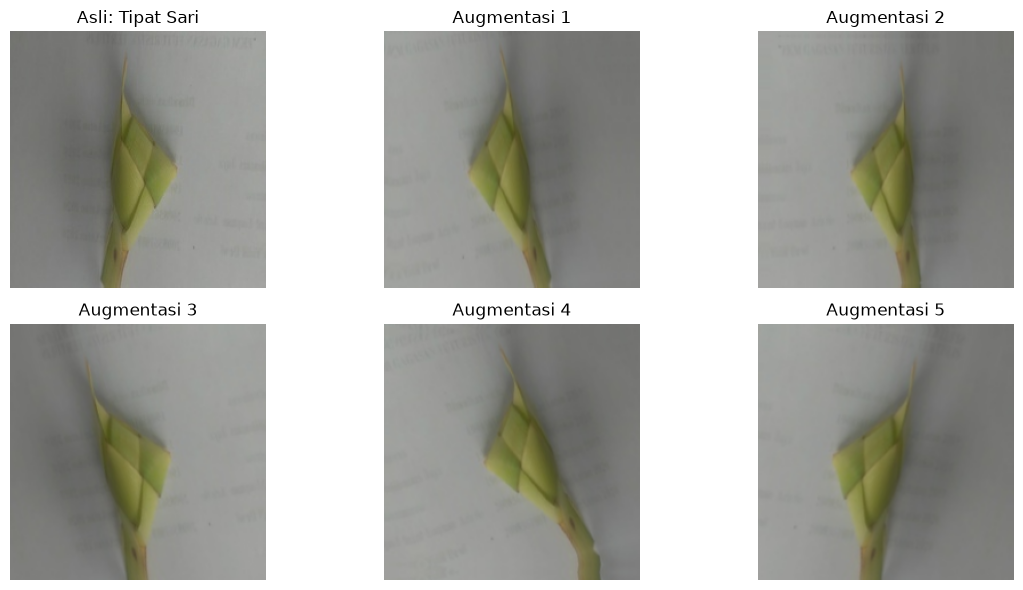


AUGMENTASI SELESAI
Jumlah kelas       : 10
Ukuran gambar      : (224, 224)
Batch size         : 16
Augmentasi         : Training saja
Validation         : Tanpa augmentasi
Testing            : Tanpa augmentasi

Dataset siap untuk tahap persiapan MobileNetV2.


In [5]:

from pathlib import Path
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. KONFIGURASI
# ==========================================

DATA_DIR = Path(
    r"C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Preprocessed"
)

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "validation"
TEST_DIR = DATA_DIR / "test"

for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    if not folder.exists():
        raise FileNotFoundError(
            f"Folder tidak ditemukan: {folder}\n"
            "Pastikan preprocessing dan pembagian dataset "
            "sudah berhasil dijalankan."
        )

# ==========================================
# 2. MEMUAT DATASET
# ==========================================

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Daftar kelas:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")

print(f"\nJumlah kelas: {num_classes}")

# Pastikan nama dan urutan kelas konsisten
assert class_names == val_ds.class_names
assert class_names == test_ds.class_names

# ==========================================
# 3. MEMBUAT AUGMENTASI
# ==========================================

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.05,
        fill_mode="reflect",
        seed=SEED
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect",
        seed=SEED + 1
    ),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.05, 0.10),
        width_factor=(-0.05, 0.10),
        fill_mode="reflect",
        seed=SEED + 2
    ),
    tf.keras.layers.RandomFlip(
        mode="horizontal",
        seed=SEED + 3
    )
], name="data_augmentation")

# ==========================================
# 4. AUGMENTASI KHUSUS TRAINING
# ==========================================

# Dataset training tetap menyimpan gambar asli di disk.
# Augmentasi diterapkan secara acak ketika gambar dibaca.
AUTOTUNE = tf.data.AUTOTUNE

train_augmented = train_ds.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    ),
    num_parallel_calls=AUTOTUNE
)

# Validation dan testing tidak diaugmentasi.
# Prefetch membantu proses pembacaan data.
train_augmented = train_augmented.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# ==========================================
# 5. VISUALISASI HASIL AUGMENTASI
# ==========================================

# Ambil satu batch gambar training
images, labels = next(iter(train_ds))

# Tampilkan satu gambar asli dan beberapa variasinya
original_image = images[0]
original_label = class_names[int(labels[0])]

plt.figure(figsize=(12, 6))

plt.subplot(2, 3, 1)
plt.imshow(
    tf.cast(original_image, tf.uint8).numpy()
)
plt.title(f"Asli: {original_label}")
plt.axis("off")

for i in range(5):
    augmented_image = data_augmentation(
        tf.expand_dims(original_image, axis=0),
        training=True
    )[0]

    plt.subplot(2, 3, i + 2)
    plt.imshow(
        tf.cast(
            tf.clip_by_value(augmented_image, 0, 255),
            tf.uint8
        ).numpy()
    )
    plt.title(f"Augmentasi {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================
# 6. RINGKASAN
# ==========================================

print("\nAUGMENTASI SELESAI")
print(f"Jumlah kelas       : {num_classes}")
print(f"Ukuran gambar      : {IMAGE_SIZE}")
print(f"Batch size         : {BATCH_SIZE}")
print("Augmentasi         : Training saja")
print("Validation         : Tanpa augmentasi")
print("Testing            : Tanpa augmentasi")
print("\nDataset siap untuk tahap persiapan MobileNetV2.")


Found 405 files belonging to 10 classes.
Found 89 files belonging to 10 classes.
Found 93 files belonging to 10 classes.
Kelas: ['Tipat Dampulan', 'Tipat Gatep', 'Tipat Gong', 'Tipat Kukur', 'Tipat Lepet', 'Tipat Nasi', 'Tipat Pengambean', 'Tipat Sari', 'Tipat Sirikan', 'Tipat Taluh']
Jumlah kelas: 10
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 32s 3us/step


Model: "Tipat_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20


C:\Users\Ryan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.2716 - loss: 2.0859
Epoch 1: val_loss improved from None to 1.38218, saving model to C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model\mobilenetv2_transfer_learning.keras

Epoch 1: finished saving model to C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model\mobilenetv2_transfer_learning.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 13s 255ms/step - accuracy: 0.2716 - loss: 2.0859 - val_accuracy: 0.5730 - val_loss: 1.3822 - learning_rate: 0.0010
Epoch 2/20
25/26 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.6550 - loss: 1.1040
Epoch 2: val_loss improved from 1.38218 to 0.91912, saving model to C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model\mobilenetv2_transfer_learning.keras

Epoch 2: finished saving model to C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model\mobilenetv2_transfer_learning.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/step - accuracy: 0.6543 - loss: 1.1032 - val_a

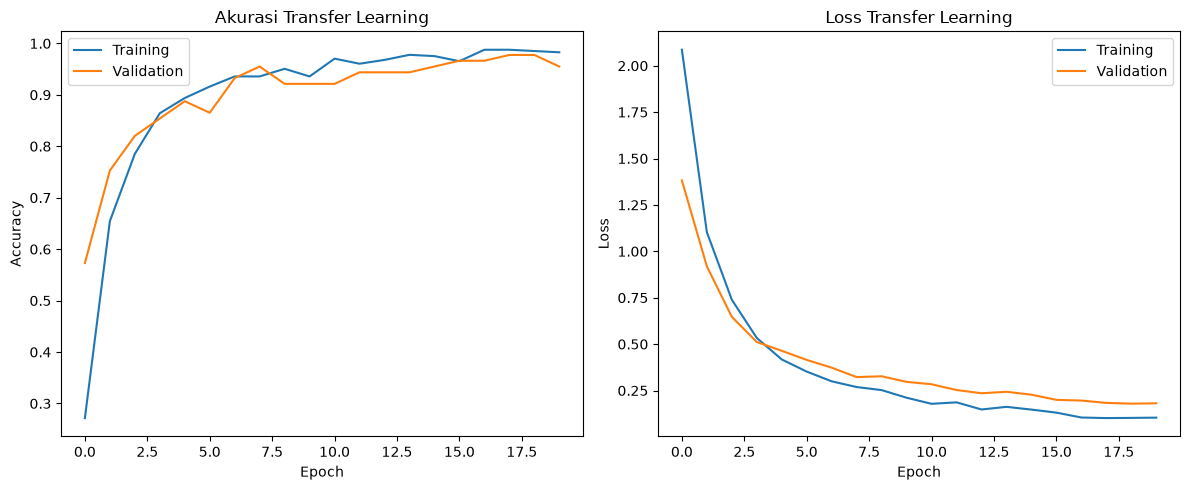


Tahap berikutnya: fine-tuning MobileNetV2.


In [6]:

from pathlib import Path
import tensorflow as tf
import matplotlib.pyplot as plt
import json

# ==========================================
# 1. KONFIGURASI
# ==========================================

DATA_DIR = Path(
    r"C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Preprocessed"
)

MODEL_DIR = DATA_DIR.parent / "Tipat_Model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "mobilenetv2_transfer_learning.keras"

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 20
SEED = 42

tf.keras.utils.set_random_seed(SEED)

# ==========================================
# 2. MEMUAT DATASET
# ==========================================

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "validation"
TEST_DIR = DATA_DIR / "test"

for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    if not folder.exists():
        raise FileNotFoundError(
            f"Folder tidak ditemukan: {folder}"
        )

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

assert class_names == val_ds.class_names
assert class_names == test_ds.class_names

print("Kelas:", class_names)
print("Jumlah kelas:", num_classes)

# Simpan urutan kelas untuk prediksi selanjutnya
with open(MODEL_DIR / "class_names.json", "w",
          encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)

# ==========================================
# 3. PREPROCESSING MOBILENETV2
# ==========================================

preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
AUTOTUNE = tf.data.AUTOTUNE

# Augmentasi diterapkan hanya pada training.
# Input masih berada pada rentang 0-255.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        0.05, fill_mode="reflect", seed=SEED
    ),
    tf.keras.layers.RandomTranslation(
        0.05, 0.05, fill_mode="reflect", seed=SEED + 1
    ),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.05, 0.10),
        width_factor=(-0.05, 0.10),
        fill_mode="reflect",
        seed=SEED + 2
    ),
    tf.keras.layers.RandomFlip(
        "horizontal", seed=SEED + 3
    )
], name="data_augmentation")

def prepare_train(images, labels):
    images = data_augmentation(images, training=True)
    images = preprocess_input(images)
    return images, labels

def prepare_eval(images, labels):
    images = preprocess_input(images)
    return images, labels

train_ready = train_ds.map(
    prepare_train,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ready = val_ds.map(
    prepare_eval,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ready = test_ds.map(
    prepare_eval,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

# ==========================================
# 4. MEMUAT MOBILENETV2 PRA-LATIH
# ==========================================

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Bekukan seluruh backbone pada tahap transfer learning
base_model.trainable = False

# ==========================================
# 5. MEMBANGUN MODEL KLASIFIKASI
# ==========================================

inputs = tf.keras.Input(shape=(224, 224, 3))

# Backbone tetap dalam mode inference agar BatchNorm stabil
x = base_model(inputs, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)

outputs = tf.keras.layers.Dense(
    num_classes,
    activation="softmax",
    name="classification_output"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="Tipat_MobileNetV2"
)

# ==========================================
# 6. KOMPILASI MODEL
# ==========================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ==========================================
# 7. CALLBACKS
# ==========================================

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# ==========================================
# 8. TRAINING TRANSFER LEARNING
# ==========================================

history = model.fit(
    train_ready,
    validation_data=val_ready,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Simpan model akhir dengan bobot terbaik
model.save(str(MODEL_PATH))

print("\nTRANSFER LEARNING SELESAI")
print("Model tersimpan di:", MODEL_PATH)

# ==========================================
# 9. VISUALISASI TRAINING
# ==========================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Akurasi Transfer Learning")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss Transfer Learning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

print("\nTahap berikutnya: fine-tuning MobileNetV2.")


Jumlah seluruh layer: 154
Jumlah layer yang dapat dilatih: 19
Epoch 1/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.9753 - loss: 0.1016
Epoch 1: val_loss improved from None to 0.14173, saving model to C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model\mobilenetv2_fine_tuned.keras

Epoch 1: finished saving model to C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model\mobilenetv2_fine_tuned.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 14s 266ms/step - accuracy: 0.9753 - loss: 0.1016 - val_accuracy: 0.9888 - val_loss: 0.1417 - learning_rate: 1.0000e-05
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.9901 - loss: 0.0613
Epoch 2: val_loss improved from 0.14173 to 0.12466, saving model to C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model\mobilenetv2_fine_tuned.keras

Epoch 2: finished saving model to C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model\mobilenetv2_fine_tuned.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 202

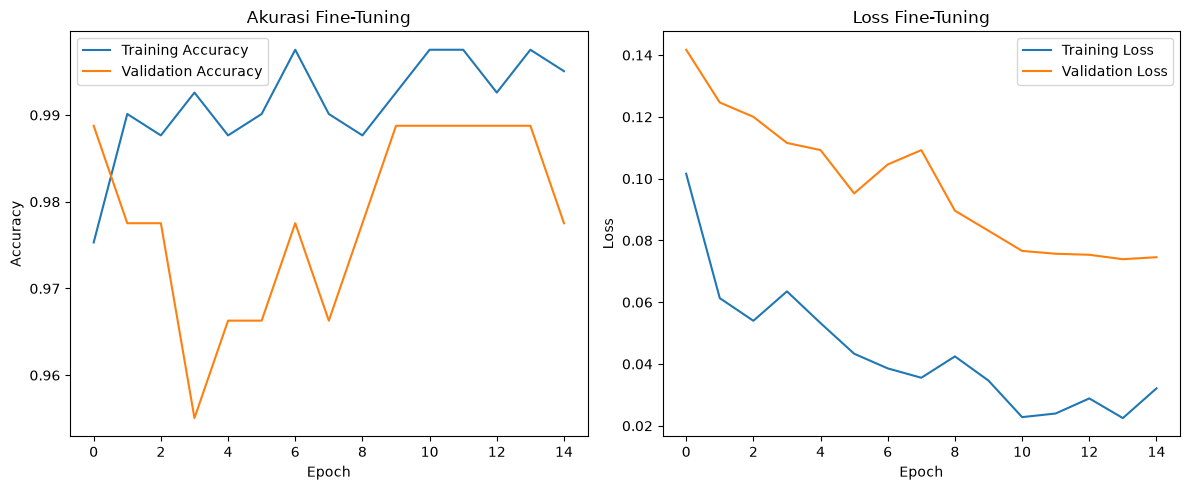

In [7]:

import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. KONFIGURASI
# ==========================================

FINE_TUNE_EPOCHS = 15
FINE_TUNE_LR = 1e-5

MODEL_DIR = Path(
    r"C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model"
)

FINE_TUNED_MODEL_PATH = (
    MODEL_DIR / "mobilenetv2_fine_tuned.keras"
)

# ==========================================
# 2. PASTIKAN MODEL TRANSFER LEARNING ADA
# ==========================================

if "model" not in globals() or "base_model" not in globals():
    raise RuntimeError(
        "Model transfer learning belum tersedia. "
        "Jalankan training sebelumnya terlebih dahulu."
    )

# ==========================================
# 3. MEMBUKA SEBAGIAN LAYER AKHIR
# ==========================================

base_model.trainable = True

# Bekukan semua layer terlebih dahulu
for layer in base_model.layers:
    layer.trainable = False

# Buka sekitar 30 layer terakhir.
# BatchNormalization tetap dibekukan untuk stabilitas.
for layer in base_model.layers[-30:]:
    if not isinstance(
        layer, tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True

print("Jumlah seluruh layer:", len(base_model.layers))
print(
    "Jumlah layer yang dapat dilatih:",
    sum(layer.trainable for layer in base_model.layers)
)

# ==========================================
# 4. KOMPILASI ULANG MODEL
# ==========================================

# WAJIB compile ulang setelah mengubah trainable.
# Learning rate dibuat kecil agar bobot pralatih
# tidak berubah terlalu drastis.
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LR
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================================
# 5. CALLBACKS
# ==========================================

callbacks_fine_tune = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(FINE_TUNED_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# ==========================================
# 6. TRAINING FINE-TUNING
# ==========================================

history_fine = model.fit(
    train_ready,
    validation_data=val_ready,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks_fine_tune
)

# Simpan bobot hasil fine-tuning yang sedang aktif
model.save(str(FINE_TUNED_MODEL_PATH))

print("\nFINE-TUNING SELESAI")
print("Model tersimpan di:", FINE_TUNED_MODEL_PATH)

# ==========================================
# 7. VISUALISASI HASIL
# ==========================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    history_fine.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history_fine.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("Akurasi Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    history_fine.history["loss"],
    label="Training Loss"
)
plt.plot(
    history_fine.history["val_loss"],
    label="Validation Loss"
)
plt.title("Loss Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


Model berhasil dimuat.
Jumlah kelas: 10
Kelas: ['Tipat Dampulan', 'Tipat Gatep', 'Tipat Gong', 'Tipat Kukur', 'Tipat Lepet', 'Tipat Nasi', 'Tipat Pengambean', 'Tipat Sari', 'Tipat Sirikan', 'Tipat Taluh']
Found 93 files belonging to 10 classes.
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 134ms/step - accuracy: 0.9355 - loss: 0.3645

HASIL EVALUASI TESTING
Test Loss     : 0.3645
Test Accuracy : 93.55%
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 393ms/step

CLASSIFICATION REPORT
                  precision    recall  f1-score   support

  Tipat Dampulan     1.0000    0.9167    0.9565        12
     Tipat Gatep     0.7778    0.8750    0.8235         8
      Tipat Gong     0.9167    1.0000    0.9565        11
     Tipat Kukur     1.0000    1.0000    1.0000         8
     Tipat Lepet     1.0000    0.6250    0.7692         8
      Tipat Nasi     0.8889    1.0000    0.9412         8
Tipat Pengambean     1.0000    1.0000    1.0000         9
      Tipat Sari     0.8182    1.0000    0.9000         9
   Tipat Sirikan     1.0000

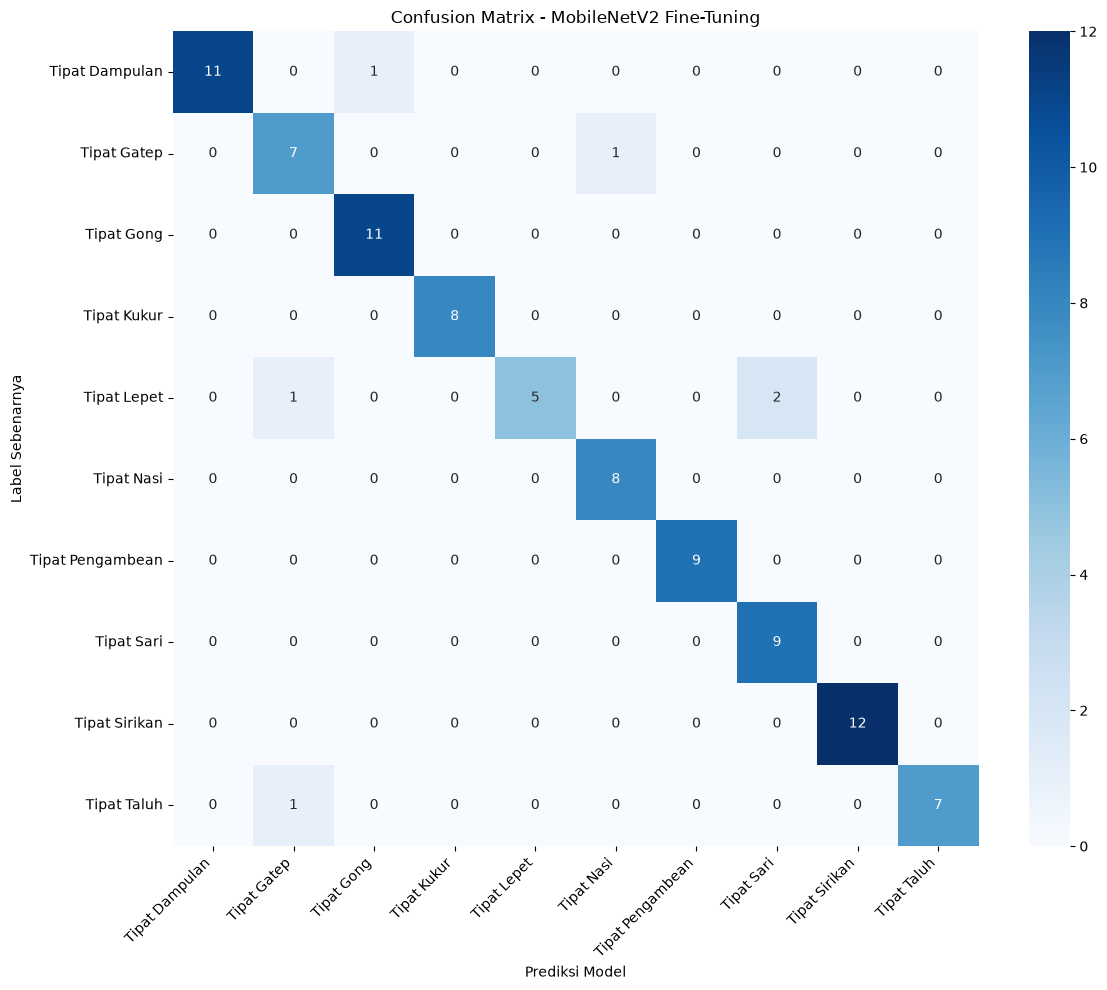


RINGKASAN PREDIKSI
Total data testing : 93
Prediksi benar     : 87
Prediksi salah     : 6

Evaluasi selesai.


In [8]:

from pathlib import Path
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# ==========================================
# 1. KONFIGURASI
# ==========================================

DATA_DIR = Path(
    r"C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Preprocessed"
)

MODEL_PATH = Path(
    r"C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model\mobilenetv2_fine_tuned.keras"
)

CLASS_NAMES_PATH = Path(
    r"C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_Model\class_names.json"
)

TEST_DIR = DATA_DIR / "test"

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16

# ==========================================
# 2. VALIDASI FILE
# ==========================================

for path in [MODEL_PATH, CLASS_NAMES_PATH, TEST_DIR]:
    if not path.exists():
        raise FileNotFoundError(
            f"File atau folder tidak ditemukan: {path}"
        )

# ==========================================
# 3. MEMUAT MODEL DAN NAMA KELAS
# ==========================================

model = tf.keras.models.load_model(MODEL_PATH)

with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as f:
    class_names = json.load(f)

print("Model berhasil dimuat.")
print("Jumlah kelas:", len(class_names))
print("Kelas:", class_names)

# ==========================================
# 4. MEMUAT TEST SET
# ==========================================

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Pastikan urutan kelas konsisten
if test_ds.class_names != class_names:
    raise ValueError(
        "Urutan kelas pada test set tidak sesuai "
        "dengan class_names.json."
    )

# MobileNetV2 membutuhkan preprocessing input
preprocess_input = (
    tf.keras.applications.mobilenet_v2.preprocess_input
)

AUTOTUNE = tf.data.AUTOTUNE

test_ready = test_ds.map(
    lambda images, labels: (
        preprocess_input(images),
        labels
    ),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

# ==========================================
# 5. MENGHITUNG LOSS DAN ACCURACY
# ==========================================

test_loss, test_accuracy = model.evaluate(
    test_ready,
    verbose=1
)

print("\n" + "=" * 55)
print("HASIL EVALUASI TESTING")
print("=" * 55)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

# ==========================================
# 6. PREDIKSI TEST SET
# ==========================================

y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ready
])

y_prob = model.predict(test_ready, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# ==========================================
# 7. CLASSIFICATION REPORT
# ==========================================

print("\nCLASSIFICATION REPORT")
print("=" * 75)

print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# ==========================================
# 8. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - MobileNetV2 Fine-Tuning")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Sebenarnya")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ==========================================
# 9. RINGKASAN PREDIKSI
# ==========================================

print("\nRINGKASAN PREDIKSI")
print("=" * 55)

total_data = len(y_true)
jumlah_benar = int(np.sum(y_true == y_pred))
jumlah_salah = total_data - jumlah_benar

print(f"Total data testing : {total_data}")
print(f"Prediksi benar     : {jumlah_benar}")
print(f"Prediksi salah     : {jumlah_salah}")

print("\nEvaluasi selesai.")
